# 06 - MLP with feature selection, and comparison of all models

- Goal: find how few attributes the MLP needs, then compare the best models of module 1.

- Reproduces: paper Section 4.1.3 and Table 11, then Table 9. The planned notebook 09 is merged into this one.

- Needs: notebooks 03, 04 and 05 (reads results/baselines.csv, results/mlp.csv and results/rankings.csv). Writes results/mlp_features.csv.

- Expected run time: about 7 minutes on a GPU with 10 repeats. A CPU would be slower.

## 1. Setup
QUICK_TEST = True runs a tiny version to check the code: 3 repeats, 1,500 rows, 2 epochs and only k = 1 to 3. These saved results come from the real run, with QUICK_TEST = False.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Windows: set before the other imports

import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import (COLOURS, METRICS, RESULT_DIR, add_balanced, get_metrics, load_data, make_inputs,
                   paired_test, predict_mlp, save_results, set_style, show_table, split_data, train_mlp)

QUICK_TEST = False  # True: tiny run to check the code, not for results
N_REPEATS = 10  # paper uses 100
MAX_EPOCHS = 300
HIDDEN = 10  # the paper's best MLP
K_VALUES = list(range(1, 11))
PREFIX = ""

if QUICK_TEST:
    N_REPEATS = 3
    MAX_EPOCHS = 2
    K_VALUES = [1, 2, 3]
    PREFIX = "quick_"

set_style()
df = load_data()
if QUICK_TEST:
    df = df.sample(1500, random_state=0)
rankings = pd.read_csv(f"{RESULT_DIR}/rankings.csv")
FILTERS = {"Correlation": "correlation", "Mutual information": "mutual_information", "mRMR": "mrmr"}

## 2. Feed the top-k attributes to the MLP
k is the number of top-ranked attributes we keep. For each of the three filters from notebook 05, and each k from 1 to 10, we take the top k attributes and one-hot code the categorical ones among them. 

Then we train the MLP (a simple neural network) with 10 hidden neurons on oversampled data, which means purchase rows are copied in the train part until both classes are equal.

In [2]:
start = time.time()
rows = []
for name, col in FILTERS.items():
    for k in K_VALUES:
        X, y = make_inputs(df, rankings[col].head(k).tolist())
        for repeat in range(N_REPEATS):
            X_tr, X_te, y_tr, y_te = split_data(X, y, seed=repeat, oversample=True)
            model, _ = train_mlp(X_tr, y_tr, HIDDEN, seed=repeat, max_epochs=MAX_EPOCHS)
            scores = get_metrics(y_te, predict_mlp(model, X_te))
            rows.append({"model": name, "setting": f"k={k}", "repeat": repeat, **scores})

res = save_results(rows, f"{PREFIX}mlp_features")
res["k"] = res["setting"].str[2:].astype(int)
print(f"Took {(time.time() - start) / 60:.1f} minutes")

Took 7.2 minutes


## 3. Accuracy and F1 against k
The star on each line marks the best k of that filter. Accuracy and F1 are converted to a 50/50 test set, the basis the paper's figures appear to fit (**this is our reading**). We use it because natural-test accuracy favours models that rarely predict a purchase. 

**Limitation**: choosing the best k from test results is slightly optimistic. As we read it, the paper does the same.

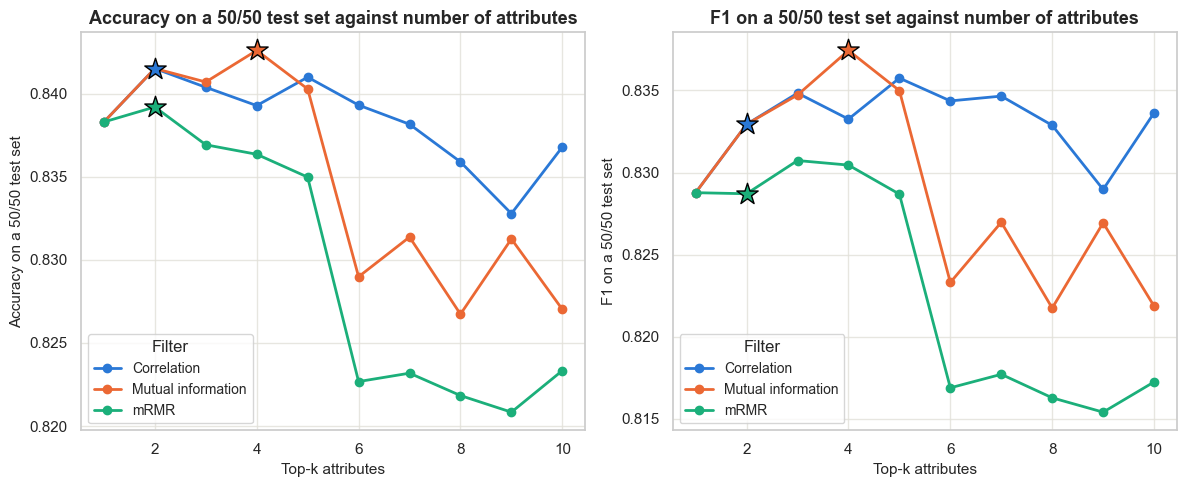

In [ ]:
means = add_balanced(res.groupby(["model", "k"])[METRICS].mean().reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, label in zip(axes, ["accuracy_5050", "f1_5050"], ["Accuracy on a 50/50 test set", "F1 on a 50/50 test set"]):
    for colour, name in zip(COLOURS, FILTERS):
        part = means[means["model"] == name]
        ax.plot(part["k"], part[metric], marker="o", color=colour, linewidth=2, label=name)
        best = part.loc[part["accuracy_5050"].idxmax()]
        ax.scatter(best["k"], best[metric], marker="*", s=260, color=colour, edgecolor="black", zorder=3)
    ax.set_title(f"{label} against number of attributes")
    ax.set_xlabel("Top-k attributes")
    ax.set_ylabel(label)
    ax.legend(title="Filter")


plt.tight_layout()
plt.show()

- Very small k already works well. On the 50/50 basis, PageValues alone (k = 1) gives 83.83% under all three filters, because it is ranked first by all of them. 
- The lines stay fairly flat up to about k = 5, and then mutual information and mRMR drop. For mRMR, k = 6, the paper's choice, gives 82.27%, lower than its k = 2 at 83.92%. This difference is unlikely to be just chance (p below 0.01).

## 4. Table 11: best k per filter
The best k is the one with the highest mean accuracy on a 50/50 test set. 

TPR (true positive rate) is the share of real buyers found, and TNR (true negative rate) is the share of non-buyers labelled correctly.
In the code table that follows, compare the "(50/50 test)" columns with the paper's accuracy and F1.

In [4]:
paper_t11 = {"Correlation": (9, 84.32, 0.84, 0.85, 0.84), "Mutual information": (10, 84.11, 0.84, 0.85, 0.84),
             "mRMR": (6, 87.94, 0.84, 0.92, 0.87)}
best_k = {name: int(means[means["model"] == name].set_index("k")["accuracy_5050"].idxmax()) for name in FILTERS}

rows = []
for name, k in best_k.items():
    m = add_balanced(means[(means["model"] == name) & (means["k"] == k)]).iloc[0]
    p = paper_t11[name]
    rows.append({"Filter": name, "k": k, "k (paper)": p[0],
                 "Accuracy %": m["accuracy"] * 100, "Accuracy % (50/50 test)": m["accuracy_5050"] * 100,
                 "Accuracy % (paper)": p[1], "TPR": m["tpr"], "TPR (paper)": p[2], "TNR": m["tnr"],
                 "TNR (paper)": p[3], "F1": m["f1"], "F1 (50/50 test)": m["f1_5050"], "F1 (paper)": p[4]})
show_table(pd.DataFrame(rows).set_index("Filter"), f"Table 11: best k per filter, {N_REPEATS} repeats",
           best=["Accuracy % (50/50 test)", "F1 (50/50 test)"])

,k,k (paper),Accuracy %,Accuracy % (50/50 test),Accuracy % (paper),TPR,TPR (paper),TNR,TNR (paper),F1,F1 (50/50 test),F1 (paper)
Filter,,,,,,,,,,,,
Correlation,2,9,87.69,84.15,84.32,0.79,0.84,0.89,0.85,0.67,0.83,0.84
Mutual information,4,10,86.45,84.26,84.11,0.81,0.84,0.87,0.85,0.65,0.84,0.84
mRMR,2,6,88.15,83.92,87.94,0.78,0.84,0.90,0.92,0.67,0.83,0.87


- Correlation and mutual information land very close to the paper (84.15% against 84.32%, and 84.26% against 84.11%). mRMR is about 4 points below the paper's 87.94%. 
- We also need far fewer attributes than the paper: 2, 4 and 2 against its 9, 10 and 6. We are not sure why.

## 5. Paired t-tests between the filters
A paired t-test compares two filters one repeat at a time, on the same splits. Each filter uses its own best k. When we call a difference significant, we mean it is unlikely to be just chance. 

In this table, ** mean p < 0.01, * means p < 0.05, and N.S. means not significant. 

In [5]:
def best_runs(name):
    """Per-repeat rows of one filter at its best k."""
    part = res[(res["model"] == name) & (res["k"] == best_k[name])]
    return part.sort_values("repeat")

pairs = []
for a, b in [("mRMR", "Correlation"), ("mRMR", "Mutual information"), ("Correlation", "Mutual information")]:
    out = {"Pair": f"{a} vs {b}"}
    for metric in METRICS:
        out[metric] = paired_test(best_runs(a)[metric].values, best_runs(b)[metric].values)[1]
    pairs.append(out)
pd.DataFrame(pairs)

,Pair,accuracy,tpr,tnr,f1
0,mRMR vs Correlation,**,**,**,**
1,mRMR vs Mutual information,**,**,**,**
2,Correlation vs Mutual information,**,**,**,**


Every difference in this table is marked as significant. But be careful with the direction. 

mRMR has the highest natural-test accuracy (88.15%) because it has the highest TNR, but the 50/50 tests in section 6 show mRMR as the lowest of the three.

## 6. Table 9: best models of module 1
We take the best oversampled C4.5 and RBF SVM from notebook 03, the best oversampled MLP from notebook 04, and our final model, which is the MLP on the top mRMR attributes. An inner join on repeat keeps only the repeats found in every file, so the tests stay paired.

In [ ]:
base = pd.read_csv(f"{RESULT_DIR}/baselines.csv")
mlp = pd.read_csv(f"{RESULT_DIR}/{PREFIX}mlp.csv")
base = base[base["setting"] == "oversampled"]
mlp = mlp[mlp["setting"] == "oversampled"]


# Best hidden size on the 50/50 basis, which is what the paper's figures fit.
best_mlp = add_balanced(mlp.groupby("model")[METRICS].mean())["accuracy_5050"].idxmax()
print("Best MLP:", best_mlp, "| mRMR best k:", best_k["mRMR"])

models = {
    "C4.5": base[base["model"] == "C4.5"],
    "MLP": mlp[mlp["model"] == best_mlp],
    "RBF SVM": base[base["model"] == "SVM RBF"],
    "MLP mRMR": best_runs("mRMR"),
}


# Inner join: keep the repeats found in every model.
keep = set.intersection(*[set(part["repeat"]) for part in models.values()])
models = {name: part[part["repeat"].isin(keep)].sort_values("repeat") for name, part in models.items()}
print("Repeats used:", len(keep))
final = pd.concat([part[["repeat"] + METRICS].assign(model=name) for name, part in models.items()])

Best MLP: MLP 10 | mRMR best k: 2
Repeats used: 10


- The best MLP on the 50/50 basis is the one with 10 hidden neurons, and the best mRMR k is 2. All 10 repeats are used.

This table shows the paper's Table 9 next to our means, with paired tests between models 1 = C4.5, 2 = MLP and 3 = RBF SVM. 

The code table first shows natural-test accuracy and F1, and then a second table converts them to a 50/50 test set. 

The markdown table below uses the 50/50 basis, which is the fair comparison with the paper.

| Measure | C4.5 (ours) | C4.5 (paper) | MLP (ours) | MLP (paper) | RBF SVM (ours) | RBF SVM (paper) |
|---|---|---|---|---|---|---|
| Accuracy % on a 50/50 test set | 82.57 | 82.34 | 81.11 | 87.24 | 82.37 | 84.88 |
| TPR | 0.82 | 0.79 | 0.76 | 0.84 | 0.75 | 0.75 |
| TNR | 0.83 | 0.85 | 0.87 | 0.92 | 0.90 | 0.94 |
| F1 on a 50/50 test set | 0.82 | 0.82 | 0.80 | 0.86 | 0.81 | 0.82 |

In [7]:
paper_t9 = {"accuracy": (82.34, 87.24, 84.88), "tpr": (0.79, 0.84, 0.75), "tnr": (0.85, 0.92, 0.94), "f1": (0.82, 0.86, 0.82)}
final_means = add_balanced(final.groupby("model")[METRICS].mean())

rows = []
for metric in METRICS:
    scale = 100 if metric == "accuracy" else 1
    p = paper_t9[metric]
    rows.append({
        "Metric": metric, "C4.5": final_means.loc["C4.5", metric] * scale, "C4.5 (paper)": p[0],
        "MLP": final_means.loc["MLP", metric] * scale, "MLP (paper)": p[1],
        "RBF SVM": final_means.loc["RBF SVM", metric] * scale, "RBF SVM (paper)": p[2],
        "MLP mRMR": final_means.loc["MLP mRMR", metric] * scale,
        "1-2": paired_test(models["C4.5"][metric].values, models["MLP"][metric].values)[1],
        "1-3": paired_test(models["C4.5"][metric].values, models["RBF SVM"][metric].values)[1],
        "2-3": paired_test(models["MLP"][metric].values, models["RBF SVM"][metric].values)[1],
    })
display(show_table(pd.DataFrame(rows).set_index("Metric"), f"Table 9: best models, {len(keep)} repeats"))

# The same four models converted to a 50/50 test set, to compare with the paper's accuracy and F1.
converted = final_means[["accuracy_5050", "f1_5050"]].copy()
converted["accuracy_5050"] = converted["accuracy_5050"] * 100
show_table(converted, "Accuracy % and F1 on a 50/50 test set")

,C4.5,C4.5 (paper),MLP,MLP (paper),RBF SVM,RBF SVM (paper),MLP mRMR,1-2,1-3,2-3
Metric,,,,,,,,,,
accuracy,83.10,82.34,84.91,87.24,87.63,84.88,88.15,**,**,**
tpr,0.82,0.79,0.76,0.84,0.75,0.75,0.78,**,**,N.S.
tnr,0.83,0.85,0.87,0.92,0.90,0.94,0.90,**,**,**
f1,0.60,0.82,0.61,0.86,0.65,0.82,0.67,N.S.,**,**


,accuracy_5050,f1_5050
model,,
C4.5,82.57,0.82
MLP,81.11,0.80
MLP mRMR,83.92,0.83
RBF SVM,82.37,0.81


**!! Here we do not match the paper. The paper finds the MLP clearly best. We find the full MLP lowest of the three on accuracy on the 50/50 basis. C4.5 is very close to the paper, RBF SVM is lower, and the MLP is the furthest below.**

### Paired tests on the 50/50 basis
The tests above use natural-test accuracy and F1. Here we convert accuracy and F1 to a 50/50 test set for each repeat.

In this table, ** mean p < 0.01, * means p < 0.05, and N.S. means not significant.

In [8]:
pool = {name: best_runs(name) for name in FILTERS}
pool.update(models)
for name in ["MLP 20", "MLP 40"]:
    pool[name] = mlp[mlp["model"] == name]

pair_list = [("MLP", "C4.5"), ("MLP", "RBF SVM"), ("C4.5", "RBF SVM"), ("MLP mRMR", "C4.5"), ("MLP mRMR", "RBF SVM"),
             ("MLP mRMR", "MLP"), ("MLP", "MLP 20"), ("MLP", "MLP 40"), ("mRMR", "Correlation"),
             ("mRMR", "Mutual information"), ("Correlation", "Mutual information")]
rows = []
for a, b in pair_list:
    runs_a = add_balanced(pool[a].sort_values("repeat"))
    runs_b = add_balanced(pool[b].sort_values("repeat"))
    rows.append({"Pair": f"{a} vs {b}",
                 "Accuracy % (first)": runs_a["accuracy_5050"].mean() * 100,
                 "Accuracy % (second)": runs_b["accuracy_5050"].mean() * 100,
                 "Accuracy test": paired_test(runs_a["accuracy_5050"].values, runs_b["accuracy_5050"].values)[1],
                 "F1 (first)": runs_a["f1_5050"].mean(), "F1 (second)": runs_b["f1_5050"].mean(),
                 "F1 test": paired_test(runs_a["f1_5050"].values, runs_b["f1_5050"].values)[1]})
show_table(pd.DataFrame(rows).set_index("Pair"), "Paired tests on the 50/50 basis", digits=2)

,Accuracy % (first),Accuracy % (second),Accuracy test,F1 (first),F1 (second),F1 test
Pair,,,,,,
MLP vs C4.5,81.11,82.57,**,0.80,0.82,**
MLP vs RBF SVM,81.11,82.37,**,0.80,0.81,*
C4.5 vs RBF SVM,82.57,82.37,N.S.,0.82,0.81,**
MLP mRMR vs C4.5,83.92,82.57,**,0.83,0.82,N.S.
MLP mRMR vs RBF SVM,83.92,82.37,**,0.83,0.81,**
MLP mRMR vs MLP,83.92,81.11,**,0.83,0.80,**
MLP vs MLP 20,81.11,79.65,**,0.80,0.78,**
MLP vs MLP 40,81.11,78.57,**,0.80,0.76,**
mRMR vs Correlation,83.92,84.15,*,0.83,0.83,**


1. The full MLP is below C4.5 and RBF SVM on accuracy (81.11% against 82.57% and 82.37%), and this is unlikely to be just chance. 
2. The MLP on 2 mRMR attributes has the highest accuracy, at 83.92%. It beats C4.5, RBF SVM and the full MLP on accuracy. Its F1  beats RBF SVM but shows no significant difference from C4.5.

3. Among the filters, mRMR is below correlation and mutual information on accuracy and F1. Correlation and mutual information show no significant difference on accuracy, so we should not call mutual information clearly best. The MLP with 10 neurons beats those with 20 and 40 on accuracy and F1 (p below 0.01).

## 7. Plots of the comparison
The bars show the mean, with the standard deviation over repeats as error bars. Accuracy and F1 in this chart are natural-test values. Compare the four bars in each group.

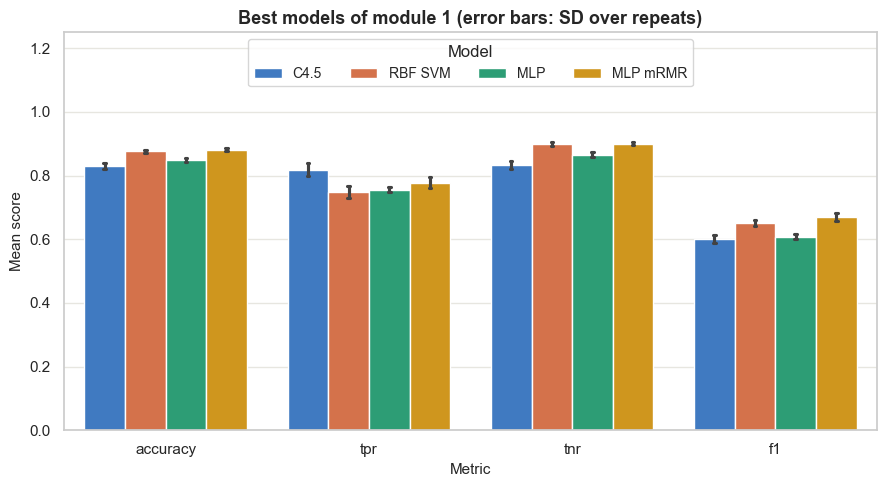

In [ ]:
order = ["C4.5", "RBF SVM", "MLP", "MLP mRMR"]
long = final.melt(id_vars=["model", "repeat"], value_vars=METRICS, var_name="metric")
fig, ax = plt.subplots()


sns.barplot(data=long, x="metric", y="value", hue="model", hue_order=order, errorbar="sd", capsize=0.05, palette=COLOURS[:4], ax=ax)
ax.set_title("Best models of module 1 (error bars: SD over repeats)")
ax.set_xlabel("Metric")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 1.25)
ax.legend(title="Model", loc="upper center", ncol=4)


plt.tight_layout()
plt.show()

On the natural test set, the MLP on mRMR attributes is highest on accuracy and F1. C4.5 has the highest TPR but the lowest TNR. The error bars are small, so the results do not change much from one split to the next.

The box plot shows the spread of natural-test accuracy across the repeats. Look at how much the boxes overlap.

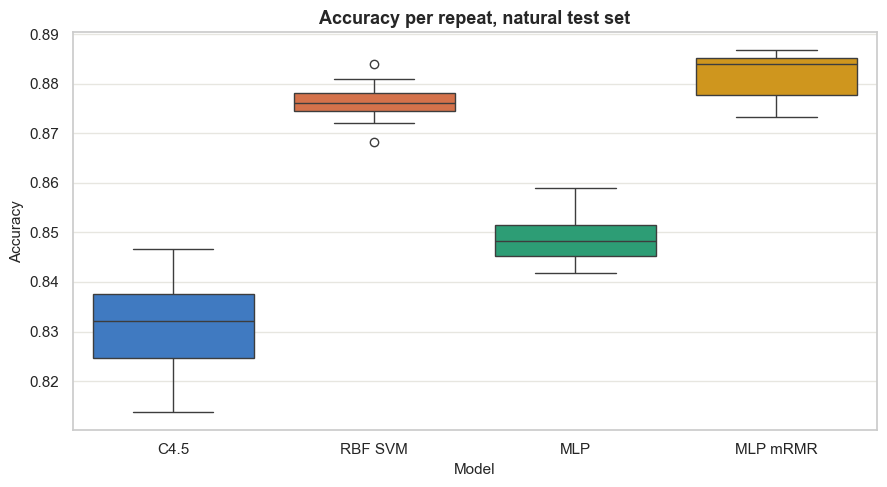

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(data=final, x="model", y="accuracy", order=order, hue="model", hue_order=order, palette=COLOURS[:4], legend=False, ax=ax)
ax.set_title("Accuracy per repeat, natural test set")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")


plt.tight_layout()
plt.show()

The boxes for RBF SVM and MLP mRMR are clearly above those for the MLP and C4.5. C4.5 has the widest spread. Remember that natural-test accuracy rewards TNR, which is why the order here differs from the 50/50 tables.

## 8. Results at a glance
This uses 10 repeats. Accuracy and F1 use the 50/50 basis.

| Model | Accuracy % (ours) | Accuracy % (paper) | F1 (ours) | F1 (paper) |
|---|---|---|---|---|
| C4.5 | 82.57 | 82.34 | 0.82 | 0.82 |
| RBF SVM | 82.37 | 84.88 | 0.81 | 0.82 |
| MLP, all attributes, 10 neurons | 81.11 | 87.24 | 0.80 | 0.86 |
| MLP, top mRMR attributes (ours k = 2, paper k = 6) | 83.92 | 87.94 | 0.83 | 0.87 |

- Our results do not support the paper's main claim that the MLP clearly wins. Our full MLP is the lowest of the three models in the paper's Table 9, while the paper has it clearly highest. 
- Feature selection helps, and the MLP on only 2 attributes has the highest accuracy here, but it is still about 4 points below the paper. Also unlike the paper, mRMR does not beat the other two filters. 
- **All 60 MLP runs in notebook 04 stopped at the 300-epoch limit, so the weak MLP result may come from our training and not from the method.**

## 9. Key takeaways

1. The filter with the highest accuracy is mutual information at k = 4, with 84.26% (paper: mRMR, k = 6, 87.94%). Mutual information and correlation show no significant difference on accuracy.

2. On the 50/50 basis, mRMR is significantly lower than both other filters on accuracy and F1, although it is significantly higher on natural-test accuracy. The paper finds mRMR significantly better.

3. Our final model is the MLP on the top 2 mRMR attributes (PageValues and Month). It reaches accuracy 88.15% on the natural test set, 83.92% on a 50/50 test set, and F1 0.83 on a 50/50 test set (paper: 87.94% and F1 0.87).

3. Does our MLP also win? No. On the 50/50 basis, the full MLP (81.11%, F1 0.80) is below C4.5 (82.57%, F1 0.82) and RBF SVM (82.37%, F1 0.81), and these differences are unlikely to be just chance. Only the MLP on 2 mRMR attributes comes out on top on accuracy. The paper has the MLP best on accuracy and F1.

4. For a real-time system, this means a shop could track very few attributes with little loss. PageValues alone reaches 83.83% on the 50/50 basis, and adding Month gives 83.92%, which is not a significant difference.